# Lokora Clasificación de productos mediante Deep Learning
**Harold Duque · Propuesta individual · 26 de octubre de 2026**

Extensión académica del proyecto Lokora desarrollado por Axiom: https://github.com/cataia-code/interledger-axiom-hackathon

## Alcance y estado
El piloto sugiere **envasados, frutas o verduras** para una fotografía de producto y requiere confirmación del vendedor. Usa Grocery Store Dataset de Klasson, Zhang y Kjellström (WACV 2019): https://github.com/marcusklasson/GroceryStoreDataset

La revisión local de las listas descargadas encontró **5.421 fotos**: 2.640 train, 296 val y 2.485 test. Se usan exclusivamente fotografías naturales, no las imágenes icónicas. El mapa es Packages → envasados, Fruit → frutas y Vegetables → verduras. El archivo LICENSE del repositorio se conserva.

**Evidencia local existente:** clase más frecuente: macro-F1 de validación 0,1818; histograma RGB + regresión logística: 0,5136. Son resultados locales archivados, no salidas de una ejecución previa de este notebook en Colab. MobileNetV2 aún no fue entrenada. Las métricas de prueba siguen pendientes.

## Cómo usarlo
1. Subir este archivo a Google Colab y ejecutar las celdas de preparación. Requiere Internet para descargar el conjunto público (aproximadamente 118 MB) y los pesos de ImageNet.
2. Las celdas iniciales preparan los datos y permiten repetir las referencias. Para entrenar la CNN, activar `ENTRENAR_CNN = True`.
3. Se recomienda GPU, aunque el código admite CPU. Las dependencias habituales están disponibles en Colab. Si falta alguna, instalar las de `ml/requirements_colab.txt`.
4. Revisar validación, prueba y errores; descargar los artefactos. Toda promoción e integración con Lokora requiere revisión humana.

El conjunto público conserva sus particiones oficiales. No hay identificador del objeto físico o de la sesión; este protocolo **no demuestra independencia por SKU**. Las fotos propias posteriores deben agruparse por producto/sesión y reservarse como evaluación del dominio de Lokora.

In [13]:
!nvidia-smi

Wed Nov 18 01:17:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [14]:
from pathlib import Path
import json, hashlib, urllib.request, importlib.util, sys
ROOT=Path('/content/lokora_ml')
(ROOT/'ml').mkdir(parents=True,exist_ok=True)
PREPARAR_PUBLICO=True
EJECUTAR_REFERENCIAS=True
ENTRENAR_CNN=True
EPOCAS_MAXIMAS=20
ZIP_URL='https://codeload.github.com/marcusklasson/GroceryStoreDataset/zip/refs/heads/master'
ZIP_SHA256='13e7c675ce247c1769d873a622420c5405ac7da8b71510adbd994460f474fd84'
print('Python:',sys.version.split()[0])

Python: 3.13.16


## Código reproducible
Las siguientes fuentes son copias completas de los scripts de la carpeta 26. El preparador conserva licencia, listas originales y huellas SHA-256. Si el archivo remoto cambia, la comprobación detiene la ejecución para que se revise la versión de datos antes de continuar.

In [15]:
(ROOT/"ml/entrenar.py").write_text('"""Experimento de clasificación de imágenes para Lokora.\n\nNo contiene datos ni métricas prefabricadas. Se ejecuta con un manifiesto real:\npython entrenar.py --manifest datos/manifest.csv --images datos --output resultados\n"""\nfrom __future__ import annotations\nimport argparse\nimport hashlib\nimport json\nimport platform\nimport time\nfrom datetime import datetime, timezone\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image, ImageOps\nfrom sklearn.dummy import DummyClassifier\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import StandardScaler\n\nCLASSES = [\'envasados\', \'frutas\', \'verduras\']\nSEED = 42\nSIZE = 224\n\n\ndef load_manifest(manifest: Path, image_root: Path) -> pd.DataFrame:\n    data = pd.read_csv(manifest, dtype=str).fillna(\'\')\n    required = [\'image_path\', \'class_name\', \'product_id\', \'source\', \'license\']\n    missing = set(required) - set(data.columns)\n    if missing:\n        raise ValueError(f\'Faltan columnas: {sorted(missing)}\')\n    if data.empty or (data[required].apply(lambda s: s.str.strip()).eq(\'\').any().any()):\n        raise ValueError(\'El manifiesto debe contener imágenes reales y completar todos los campos obligatorios.\')\n    if set(data.class_name) != set(CLASSES):\n        raise ValueError(f\'El primer experimento requiere exactamente estas clases: {CLASSES}\')\n    if data.groupby(\'product_id\').class_name.nunique().gt(1).any():\n        raise ValueError(\'Un product_id no puede tener etiquetas de clases diferentes.\')\n    hashes, paths = [], []\n    root = image_root.resolve()\n    for rel in data.image_path:\n        p = (root / rel).resolve()\n        if not p.is_relative_to(root) or not p.is_file():\n            raise ValueError(f\'Ruta inexistente o fuera de la carpeta de imágenes: {rel}\')\n        with Image.open(p) as im:\n            im.verify()\n        hashes.append(hashlib.sha256(p.read_bytes()).hexdigest())\n        paths.append(str(p))\n    data[\'sha256\'] = hashes\n    data[\'absolute_path\'] = paths\n    if data.sha256.duplicated().any():\n        raise ValueError(\'Hay imágenes idénticas. Depurarlas antes de separar los datos.\')\n    data[\'label\'] = data.class_name.map({c: i for i, c in enumerate(CLASSES)})\n    if \'official_split\' in data.columns and data.official_split.ne(\'\').all():\n        if set(data.official_split) != {\'train\', \'val\', \'test\'}:\n            raise ValueError(\'official_split debe contener train, val y test.\')\n        data[\'split\'] = data.official_split\n        for split in [\'train\', \'val\', \'test\']:\n            if set(data.loc[data.split.eq(split), \'class_name\']) != set(CLASSES):\n                raise ValueError(\'Cada partición oficial debe contener las tres clases.\')\n    else:\n        groups = data[[\'product_id\', \'class_name\']].drop_duplicates()\n        if groups.groupby(\'class_name\').size().reindex(CLASSES, fill_value=0).min() < 15:\n            raise ValueError(\'Se requieren al menos 15 grupos independientes por clase para la partición inicial; se recomiendan 30 o más.\')\n        trainval, test = train_test_split(groups, test_size=.20, random_state=SEED, stratify=groups.class_name)\n        train, val = train_test_split(trainval, test_size=.25, random_state=SEED, stratify=trainval.class_name)\n        split_map = {g: s for s, frame in [(\'train\', train), (\'val\', val), (\'test\', test)] for g in frame.product_id}\n        data[\'split\'] = data.product_id.map(split_map)\n    return data\n\n\ndef rgb_histogram(path: str) -> np.ndarray:\n    with Image.open(path) as im:\n        rgb = np.asarray(ImageOps.exif_transpose(im).convert(\'RGB\').resize((224, 224)), dtype=np.float32) / 255.\n    h = [np.histogram(rgb[:, :, c], bins=16, range=(0, 1), density=False)[0] / (224*224) for c in range(3)]\n    return np.concatenate(h + [rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1))])\n\n\ndef read_rgb(path):\n    if isinstance(path, np.ndarray):\n        path = path.item()\n    if isinstance(path, bytes):\n        path = path.decode(\'utf-8\')\n    with Image.open(path) as im:\n        return np.asarray(ImageOps.exif_transpose(im).convert(\'RGB\'), dtype=np.float32)\n\n\ndef evaluate(y, probabilities):\n    pred = np.asarray(probabilities).argmax(axis=1)\n    return {\'accuracy\': float(accuracy_score(y, pred)),\n            \'macro_f1\': float(f1_score(y, pred, labels=range(len(CLASSES)), average=\'macro\', zero_division=0)),\n            \'classification_report\': classification_report(y, pred, labels=range(len(CLASSES)), target_names=CLASSES, output_dict=True, zero_division=0),\n            \'confusion_matrix\': confusion_matrix(y, pred, labels=range(len(CLASSES))).tolist()}\n\n\ndef run(manifest: Path, image_root: Path, output: Path, epochs: int = 20):\n    import tensorflow as tf\n    import sklearn\n    import joblib\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    started = time.perf_counter()\n    tf.keras.utils.set_random_seed(SEED)\n    try:\n        tf.config.experimental.enable_op_determinism()\n    except (AttributeError, RuntimeError):\n        pass\n    stamp = datetime.now(timezone.utc).strftime(\'%Y%m%dT%H%M%S%fZ\')\n    out = output / stamp\n    out.mkdir(parents=True, exist_ok=False)\n    data = load_manifest(manifest, image_root)\n    data.drop(columns=\'absolute_path\').to_csv(out/\'manifest_con_particiones.csv\', index=False)\n    frames = {s: data[data.split.eq(s)].copy() for s in [\'train\', \'val\', \'test\']}\n    # Las proporciones son por producto; el número de fotografías puede diferir.\n    counts=pd.crosstab(data.split, data.class_name).reindex([\'train\', \'val\', \'test\'])\n    counts.to_csv(out/\'distribucion_datos.csv\')\n    print(counts)\n    hist = {s: np.stack([rgb_histogram(p) for p in f.absolute_path]) for s, f in frames.items()}\n    labels = {s: f.label.to_numpy(dtype=int) for s, f in frames.items()}\n    majority = DummyClassifier(strategy=\'most_frequent\').fit(hist[\'train\'], labels[\'train\'])\n    rgb_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight=\'balanced\', max_iter=2000, random_state=SEED))\n    rgb_model.fit(hist[\'train\'], labels[\'train\'])\n    joblib.dump(rgb_model, out/\'referencia_rgb.joblib\')\n\n    def dataset(frame, training=False):\n        ds = tf.data.Dataset.from_tensor_slices((frame.absolute_path.to_numpy(), frame.label.to_numpy(dtype=np.int32)))\n        def decode(p, y):\n            image = tf.numpy_function(read_rgb, [p], tf.float32)\n            image.set_shape([None, None, 3])\n            return tf.image.resize_with_pad(image, SIZE, SIZE), y\n        ds = ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE)\n        if training:\n            ds = ds.shuffle(len(frame), seed=SEED)\n        return ds.batch(32).prefetch(tf.data.AUTOTUNE)\n\n    ds = {s: dataset(f, training=(s == \'train\')) for s, f in frames.items()}\n    base = tf.keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), include_top=False, weights=\'imagenet\')\n    base.trainable = False\n    inputs = tf.keras.Input(shape=(SIZE, SIZE, 3), name=\'rgb_0_255\')\n    x = tf.keras.layers.RandomFlip(\'horizontal\')(inputs)\n    x = tf.keras.layers.RandomRotation(.05)(x)\n    x = tf.keras.layers.Rescaling(1./127.5, offset=-1)(x)\n    x = base(x, training=False)\n    x = tf.keras.layers.GlobalAveragePooling2D()(x)\n    x = tf.keras.layers.Dropout(.2)(x)\n    outputs = tf.keras.layers.Dense(len(CLASSES), activation=\'softmax\')(x)\n    model = tf.keras.Model(inputs, outputs, name=\'lokora_mobilenetv2\')\n    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=\'sparse_categorical_crossentropy\', metrics=[\'accuracy\'])\n    checkpoint = out/\'modelo.keras\'\n    callbacks = [tf.keras.callbacks.EarlyStopping(monitor=\'val_loss\', patience=4, restore_best_weights=True),\n                 tf.keras.callbacks.ModelCheckpoint(checkpoint, monitor=\'val_loss\', save_best_only=True)]\n    history = model.fit(ds[\'train\'], validation_data=ds[\'val\'], epochs=epochs, callbacks=callbacks)\n    model = tf.keras.models.load_model(checkpoint)\n    # Comparación y umbral exploratorio se documentan en validación. La prueba\n    # se consulta una vez al final, sin reajustar parámetros a partir de ella.\n    result = {}\n    for split in [\'val\', \'test\']:\n        probs = model.predict(ds[split], verbose=0)\n        result[split] = {\n            \'clase_mas_frecuente\': evaluate(labels[split], majority.predict_proba(hist[split])),\n            \'histograma_rgb_logistica\': evaluate(labels[split], rgb_model.predict_proba(hist[split])),\n            \'mobilenetv2\': evaluate(labels[split], probs),\n        }\n        predictions = frames[split][[\'image_path\', \'product_id\', \'class_name\']].copy()\n        predictions[\'predicted_class\'] = np.array(CLASSES)[probs.argmax(axis=1)]\n        predictions[\'max_softmax\'] = probs.max(axis=1)\n        predictions.to_csv(out/f\'predicciones_{split}.csv\', index=False)\n    best_ref = max(result[\'val\'][k][\'macro_f1\'] for k in [\'clase_mas_frecuente\', \'histograma_rgb_logistica\'])\n    candidate_selected = result[\'val\'][\'mobilenetv2\'][\'macro_f1\'] >= best_ref\n    # Metas propuestas para el piloto; no equivalen a desempeño ya alcanzado.\n    acceptance = {\'seleccionado_en_validacion\': bool(candidate_selected),\n                  \'meta_macro_f1_prueba\': .80,\n                  \'macro_f1_prueba_cumple_meta\': result[\'test\'][\'mobilenetv2\'][\'macro_f1\'] >= .80,\n                  \'estado\': \'candidato experimental; requiere revisión de errores y evaluación con vendedor\'}\n    sample = next(iter(ds[\'test\']))[0][:1]\n    model(sample, training=False).numpy()  # calentamiento antes de medir\n    latencies=[]\n    for _ in range(30):\n        t=time.perf_counter(); model(sample, training=False).numpy(); latencies.append((time.perf_counter()-t)*1000)\n    metadata = {\'run_id\': stamp, \'seed\': SEED, \'classes\': CLASSES, \'input_size\': [224,224,3],\n                \'input_range\': [0,255], \'resize\': \'tf.image.resize_with_pad\',\n                \'normalization\': \'Rescaling(1/127.5, offset=-1) incluida en el modelo\',\n                \'split\': (\'Listas oficiales del conjunto público; identidad física no disponible\' if \'official_split\' in data.columns else \'60/20/20 de grupos product_id estratificados por clase\'),\n                \'sha256_manifest\': hashlib.sha256(manifest.read_bytes()).hexdigest(),\n                \'python\': platform.python_version(), \'tensorflow\': tf.__version__,\n                \'numpy\': np.__version__, \'pandas\': pd.__version__, \'scikit_learn\':sklearn.__version__,\n                \'epochs_run\':len(history.history[\'loss\']), \'backbone_trainable\':False,\n                \'device\': [d.name for d in tf.config.list_physical_devices()],\n                \'latency_inference_only_ms_median\': float(np.median(latencies)),\n                \'latency_inference_only_ms_p95\': float(np.percentile(latencies,95)),\n                \'total_seconds\': time.perf_counter()-started,\n                \'artifact_sha256\': hashlib.sha256(checkpoint.read_bytes()).hexdigest()}\n    for name, content in [(\'metricas.json\',result),(\'metadatos.json\',metadata),(\'criterios_piloto.json\',acceptance),(\'clases.json\',CLASSES)]:\n        (out/name).write_text(json.dumps(content,indent=2,ensure_ascii=False), encoding=\'utf-8\')\n    pd.DataFrame(history.history).to_csv(out/\'historial_entrenamiento.csv\',index=False)\n    fig, axes = plt.subplots(1,2,figsize=(10,4))\n    for key, title, ax in [(\'loss\',\'Pérdida\',axes[0]),(\'accuracy\',\'Exactitud\',axes[1])]:\n        ax.plot(history.history[key],label=\'Entrenamiento\');ax.plot(history.history[\'val_\'+key],label=\'Validación\')\n        ax.set_title(title);ax.set_xlabel(\'Época desde cero\');ax.legend()\n    fig.tight_layout();fig.savefig(out/\'curvas_entrenamiento.png\',dpi=180);plt.close(fig)\n    cm = np.array(result[\'test\'][\'mobilenetv2\'][\'confusion_matrix\'])\n    fig, ax=plt.subplots(figsize=(6,5));im=ax.imshow(cm,cmap=\'Blues\');fig.colorbar(im,ax=ax)\n    ax.set_xticks(range(3),CLASSES,rotation=20);ax.set_yticks(range(3),CLASSES)\n    ax.set_xlabel(\'Predicción\');ax.set_ylabel(\'Clase real\');ax.set_title(\'Matriz de confusión en prueba\')\n    for i in range(3):\n        for j in range(3):ax.text(j,i,str(cm[i,j]),ha=\'center\',va=\'center\',color=\'white\' if cm[i,j]>cm.max()/2 else \'black\')\n    fig.tight_layout();fig.savefig(out/\'matriz_confusion.png\',dpi=180);plt.close(fig)\n    print(json.dumps({\'run\':str(out),\'test_macro_f1\':result[\'test\'][\'mobilenetv2\'][\'macro_f1\'],\'criterios\':acceptance},indent=2,ensure_ascii=False))\n    return out\n\n\nif __name__ == \'__main__\':\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--manifest\',type=Path,required=True)\n    parser.add_argument(\'--images\',type=Path,required=True)\n    parser.add_argument(\'--output\',type=Path,default=Path(\'resultados\'))\n    parser.add_argument(\'--epochs\',type=int,default=20)\n    args=parser.parse_args()\n    run(args.manifest,args.images,args.output,args.epochs)\n',encoding="utf-8")
(ROOT/"ml/preparar_grocery.py").write_text('"""Adapta el ZIP oficial sin mezclar imágenes icónicas con fotografías naturales."""\nfrom pathlib import Path\nfrom zipfile import ZipFile\nimport argparse, csv, hashlib, json\nfrom collections import Counter\n\nSOURCE=\'https://github.com/marcusklasson/GroceryStoreDataset\'\nMAPPING={\'Fruit\':\'frutas\',\'Vegetables\':\'verduras\',\'Packages\':\'envasados\'}\n\n\ndef prepare(archive: Path, output: Path):\n    output.mkdir(parents=True,exist_ok=True)\n    rows=[]; seen={}; duplicates=[]\n    with ZipFile(archive) as z:\n        root=next(n[:-len(\'dataset/classes.csv\')] for n in z.namelist() if n.endswith(\'/dataset/classes.csv\'))\n        for name in [\'README.md\',\'LICENSE\']:\n            (output/(\'GROCERY_\'+name)).write_bytes(z.read(root+name))\n        for name in [\'classes.csv\',\'train.txt\',\'val.txt\',\'test.txt\']:\n            (output/(\'original_\'+name)).write_bytes(z.read(root+\'dataset/\'+name))\n        # Se conserva primero entrenamiento, luego validación y al final prueba.\n        # Un duplicado exacto posterior se excluye y se registra, sin consultar el modelo.\n        for split in [\'train\',\'val\',\'test\']:\n            for line in z.read(root+\'dataset/\'+split+\'.txt\').decode().splitlines():\n                if not line.strip():continue\n                relative,fine,coarse=[x.strip() for x in line.split(\',\')]\n                parts=Path(relative).parts\n                if len(parts)<3 or parts[0]!=split or parts[1] not in MAPPING:\n                    raise ValueError(\'Ruta no esperada en la lista oficial: \'+relative)\n                raw=z.read(root+\'dataset/\'+relative)\n                digest=hashlib.sha256(raw).hexdigest()\n                if digest in seen:\n                    duplicates.append({\'excluded\':relative,\'kept\':seen[digest],\'sha256\':digest})\n                    continue\n                seen[digest]=relative\n                target=(output/relative).resolve()\n                if not target.is_relative_to(output.resolve()):raise ValueError(\'Ruta fuera del destino\')\n                target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(raw)\n                rows.append({\'image_path\':relative,\'class_name\':MAPPING[parts[1]],\n                             \'product_id\':\'public_image:\'+relative,\'source\':SOURCE,\'license\':\'MIT (LICENSE del repositorio)\',\n                             \'official_split\':split,\'group_status\':\'identity_not_available\',\n                             \'fine_label\':fine,\'coarse_label\':coarse,\'sha256\':digest})\n    manifest=output/\'manifest.csv\'\n    with manifest.open(\'w\',newline=\'\',encoding=\'utf-8\') as f:\n        writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)\n    summary={\'source\':SOURCE,\'archive_sha256\':hashlib.sha256(archive.read_bytes()).hexdigest(),\n             \'mapping\':MAPPING,\'images_retained\':len(rows),\'exact_duplicates_removed\':len(duplicates),\n             \'counts\':dict(sorted(Counter(r[\'official_split\']+\'/\'+r[\'class_name\'] for r in rows).items())),\n             \'split_protocol\':\'Listas oficiales train/val/test; exclusión previa de duplicados exactos si existen\',\n             \'group_limit\':\'Los metadatos no identifican el objeto físico o la sesión; product_id es un identificador de imagen y no acredita independencia por SKU.\'}\n    (output/\'resumen_dataset.json\').write_text(json.dumps(summary,ensure_ascii=False,indent=2))\n    (output/\'duplicados_excluidos.json\').write_text(json.dumps(duplicates,ensure_ascii=False,indent=2))\n    print(json.dumps(summary,ensure_ascii=False,indent=2))\n    return manifest\n\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser();p.add_argument(\'--zip\',type=Path,required=True);p.add_argument(\'--output\',type=Path,required=True)\n    args=p.parse_args();prepare(args.zip,args.output)\n',encoding="utf-8")
(ROOT/"ml/evaluar_referencias.py").write_text('"""Mide referencias en validación. No consulta métricas de prueba ni entrena la CNN."""\nfrom pathlib import Path\nimport hashlib, json, platform, sys, time\nfrom datetime import datetime, timezone\nimport numpy as np\nimport pandas as pd\nimport sklearn\nfrom sklearn.dummy import DummyClassifier\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import StandardScaler\nfrom entrenar import load_manifest, rgb_histogram, evaluate, CLASSES\n\nROOT=Path(__file__).resolve().parents[1]\nDATA=ROOT/\'datos/grocery_publico\'\nOUT=ROOT/\'resultados\'\nOUT.mkdir(exist_ok=True)\n\ndef main():\n    start=time.perf_counter()\n    data=load_manifest(DATA/\'manifest.csv\',DATA)\n    counts=pd.crosstab(data.split,data.class_name).reindex([\'train\',\'val\',\'test\'])\n    counts.to_csv(OUT/\'distribucion_dataset.csv\')\n    frames={s:data[data.split.eq(s)] for s in [\'train\',\'val\']}\n    x={s:np.stack([rgb_histogram(p) for p in f.absolute_path]) for s,f in frames.items()}\n    y={s:f.label.to_numpy(dtype=int) for s,f in frames.items()}\n    models={\'clase_mas_frecuente\':DummyClassifier(strategy=\'most_frequent\'),\n            \'histograma_rgb_logistica\':make_pipeline(StandardScaler(),LogisticRegression(class_weight=\'balanced\',max_iter=2000,random_state=42))}\n    results={}\n    for name,model in models.items():\n        model.fit(x[\'train\'],y[\'train\'])\n        results[name]=evaluate(y[\'val\'],model.predict_proba(x[\'val\']))\n    metadata={\'ejecutado_utc\':datetime.now(timezone.utc).isoformat(),\'particion_evaluada\':\'val\',\n              \'train_rows\':len(frames[\'train\']),\'val_rows\':len(frames[\'val\']),\'test_rows_sin_evaluar\':int(data.split.eq(\'test\').sum()),\n              \'classes\':CLASSES,\'python\':platform.python_version(),\'numpy\':np.__version__,\'pandas\':pd.__version__,\n              \'scikit_learn\':sklearn.__version__,\'elapsed_seconds\':time.perf_counter()-start,\n              \'sha256_manifest\':hashlib.sha256((DATA/\'manifest.csv\').read_bytes()).hexdigest(),\n              \'cnn_status\':\'Preparada sin entrenar; no hay métricas de MobileNetV2\',\n              \'source\':\'https://github.com/marcusklasson/GroceryStoreDataset\'}\n    (OUT/\'referencias_validacion.json\').write_text(json.dumps(results,ensure_ascii=False,indent=2))\n    (OUT/\'metadatos_referencias.json\').write_text(json.dumps(metadata,ensure_ascii=False,indent=2))\n    print(counts.to_string())\n    print(json.dumps({k:{m:v[m] for m in [\'accuracy\',\'macro_f1\']} for k,v in results.items()},indent=2))\n    print(\'Prueba reservada sin evaluar; MobileNetV2 pendiente de Colab.\')\n\nif __name__==\'__main__\':main()\n',encoding="utf-8")
if str(ROOT/'ml') not in sys.path: sys.path.insert(0,str(ROOT/'ml'))
print('Scripts preparados en',ROOT/'ml')

Scripts preparados en /content/lokora_ml/ml


In [16]:
MANIFEST=ROOT/'datos/grocery_publico/manifest.csv'
if PREPARAR_PUBLICO:
    archive=ROOT/'GroceryStoreDataset-master.zip'
    if not archive.exists():
        urllib.request.urlretrieve(ZIP_URL,archive)
    digest=hashlib.sha256(archive.read_bytes()).hexdigest()
    if digest != ZIP_SHA256:
        raise RuntimeError('El archivo público cambió de versión. Revisar su contenido y registrar la nueva huella antes de continuar.')
    import preparar_grocery
    MANIFEST=preparar_grocery.prepare(archive,ROOT/'datos/grocery_publico')
    print('Manifiesto listo:',MANIFEST)
else:
    print('Preparación pública desactivada. Configure MANIFEST con sus datos.')

{
  "source": "https://github.com/marcusklasson/GroceryStoreDataset",
  "archive_sha256": "13e7c675ce247c1769d873a622420c5405ac7da8b71510adbd994460f474fd84",
  "mapping": {
    "Fruit": "frutas",
    "Vegetables": "verduras",
    "Packages": "envasados"
  },
  "images_retained": 5421,
  "exact_duplicates_removed": 0,
  "counts": {
    "test/envasados": 781,
    "test/frutas": 1117,
    "test/verduras": 587,
    "train/envasados": 864,
    "train/frutas": 1142,
    "train/verduras": 634,
    "val/envasados": 100,
    "val/frutas": 111,
    "val/verduras": 85
  },
  "split_protocol": "Listas oficiales train/val/test; exclusión previa de duplicados exactos si existen",
  "group_limit": "Los metadatos no identifican el objeto físico o la sesión; product_id es un identificador de imagen y no acredita independencia por SKU."
}
Manifiesto listo: /content/lokora_ml/datos/grocery_publico/manifest.csv


## Referencias en validación
Se entrena una predicción constante de clase frecuente y una regresión logística con 54 atributos de color: 16 bins por canal RGB, medias y desviaciones. La estandarización se ajusta solo con entrenamiento. La tabla utiliza validación; esta etapa no consulta las métricas de prueba.

In [17]:
if EJECUTAR_REFERENCIAS and MANIFEST.exists():
    import evaluar_referencias
    evaluar_referencias.main()
    import pandas as pd
    from IPython.display import display
    refs=json.loads((ROOT/'resultados/referencias_validacion.json').read_text())
    display(pd.DataFrame([{'modelo':k,'accuracy_val':v['accuracy'],'macro_f1_val':v['macro_f1']} for k,v in refs.items()]))
else:
    print('Referencias sin ejecutar. Revise las opciones y el manifiesto.')

class_name  envasados  frutas  verduras
split                                  
train             864    1142       634
val               100     111        85
test              781    1117       587
{
  "clase_mas_frecuente": {
    "accuracy": 0.375,
    "macro_f1": 0.1818181818181818
  },
  "histograma_rgb_logistica": {
    "accuracy": 0.5304054054054054,
    "macro_f1": 0.5136387918452009
  }
}
Prueba reservada sin evaluar; MobileNetV2 pendiente de Colab.


,modelo,accuracy_val,macro_f1_val
0,clase_mas_frecuente,0.375000,0.181818
1,histograma_rgb_logistica,0.530405,0.513639


## Entrenar MobileNetV2
La base preentrenada en ImageNet se congela. Se añade pooling global, dropout y una capa softmax de tres salidas. El aumento de datos se aplica solo en entrenamiento; la parada temprana usa la pérdida de validación. La imagen se orienta según EXIF, se convierte a RGB y se ajusta con padding a 224 × 224. El escalado de [0,255] a [-1,1] está incluido en el modelo.

La meta inicial macro-F1 ≥ 0,80 es **un criterio propuesto**, no un resultado alcanzado. El candidato debe compararse con las referencias en validación y revisarse con fotografías locales. Las salidas softmax no tienen calibración demostrada y no detectan de manera fiable productos ajenos a las tres categorías.

In [18]:
RUN_DIR=None
if ENTRENAR_CNN:
    if not MANIFEST.exists():raise FileNotFoundError('Prepare primero los datos.')
    import entrenar
    RUN_DIR=entrenar.run(MANIFEST,MANIFEST.parent,ROOT/'resultados_cnn',epochs=EPOCAS_MAXIMAS)
else:
    print('CNN sin ejecutar. Active ENTRENAR_CNN cuando esté listo para entrenar.')

class_name  envasados  frutas  verduras
split                                  
train             864    1142       634
val               100     111        85
test              781    1117       587
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - accuracy: 0.8636 - loss: 0.3493 - val_accuracy: 0.9324 - val_loss: 0.1523
Epoch 2/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9598 - loss: 0.1226 - val_accuracy: 0.9459 - val_loss: 0.1349
Epoch 3/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 15s 100ms/step - accuracy: 0.9720 - loss: 0.0875 - val_accuracy: 0.9493 - val_loss: 0.1153
Epoch 4/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.9750 - loss: 0.0771 - val_accuracy: 0.9561 - val_loss: 0.1027
Epoch 5/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 14s 85ms/step - accuracy: 0.9852 - loss: 0.0553 - val_accuracy: 0.9561 - val_loss: 0.1014
Epoch 6/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 13s 83ms/step - accuracy: 0.9864 - loss: 0.0505 - val_accuracy: 0.9595 

## Evaluación del run y descarga
El script guarda métricas de validación y prueba para los tres modelos, curvas, matriz de confusión, referencia RGB, modelo `.keras`, clases, predicciones, particiones, hashes y versiones. Configure el experimento con validación; no ajuste hiperparámetros según prueba. La latencia reportada corresponde solo a inferencia sobre un tensor preparado después del calentamiento, no al tiempo completo de la aplicación.

,particion,modelo,macro_f1,accuracy
0,val,clase_mas_frecuente,0.181818,0.375000
1,val,histograma_rgb_logistica,0.513639,0.530405
2,val,mobilenetv2,0.968881,0.969595
3,test,clase_mas_frecuente,0.206737,0.449497
4,test,histograma_rgb_logistica,0.664240,0.680885
5,test,mobilenetv2,0.969350,0.971831


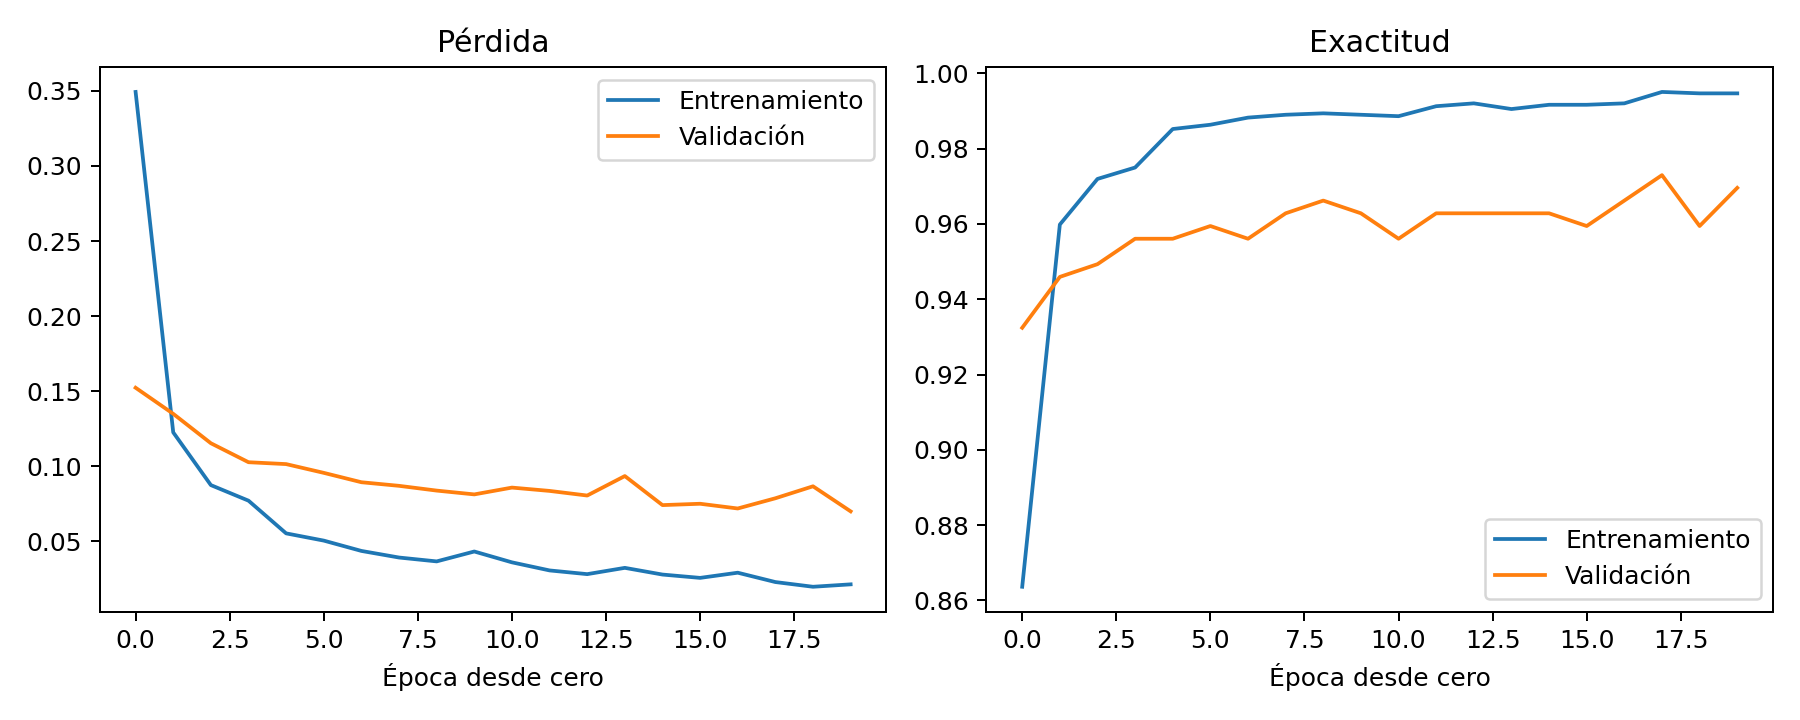

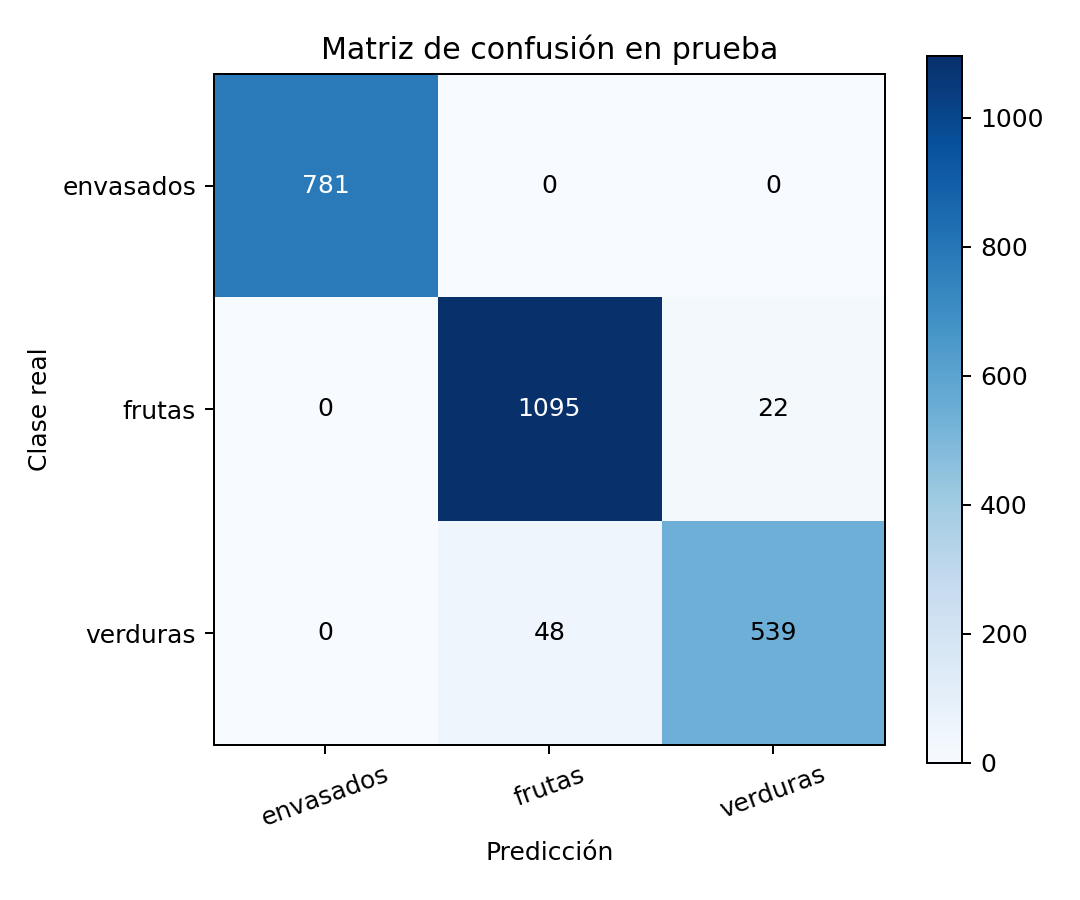

{
  "seleccionado_en_validacion": true,
  "meta_macro_f1_prueba": 0.8,
  "macro_f1_prueba_cumple_meta": true,
  "estado": "candidato experimental; requiere revisión de errores y evaluación con vendedor"
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
if RUN_DIR is not None:
    from IPython.display import display, Image
    import pandas as pd
    metrics=json.loads((RUN_DIR/'metricas.json').read_text())
    display(pd.DataFrame([{'particion':s,'modelo':k,'macro_f1':v['macro_f1'],'accuracy':v['accuracy']} for s,models in metrics.items() for k,v in models.items()]))
    for name in ['curvas_entrenamiento.png','matriz_confusion.png']:
        display(Image(filename=str(RUN_DIR/name)))
    print((RUN_DIR/'criterios_piloto.json').read_text())
    import shutil
    from google.colab import files
    files.download(shutil.make_archive(str(ROOT/'artefactos_lokora'),'zip',RUN_DIR))
else:
    print('No hay un modelo neuronal entrenado para evaluar o descargar.')

## Siguiente etapa con fotos de Lokora
Crear un manifiesto con `image_path,class_name,product_id,source,license`, sin `official_split`. El script aplicará entonces separación 60/20/20 por `product_id`, estratificada por clase, con un mínimo técnico de 15 grupos por clase y recomendación de recolectar más. Fotografías del mismo producto o sesión comparten grupo. Deduplicar también las imágenes visualmente similares. Antes de cualquier ajuste con fotos locales, conservar un conjunto local que no se use para entrenar ni escoger parámetros.

El servicio propuesto `ml/servicio_inferencia.py` consume un run revisado mediante `LOKORA_MODEL_DIR`. Express debe validar la sesión, enviar la imagen y devolver la sugerencia; el vendedor confirma y la aplicación mapea la clase global a una categoría de la tienda. Esa integración no se ha desplegado.

Para medir utilidad, comparar tiempos manuales y asistidos con orden contrabalanceado sobre productos equivalentes, registrar correcciones y latencia de extremo a extremo. No se ha medido aún ahorro comercial.